# Automatic Speech Recognition (ASR) Model Comparison
This notebook demonstrates how to compare several open-source ASR models:
- Wav2Vec2
- HuBERT
- Whisper
- Distil-Whisper

## Step 1: Setup

In [1]:
# Imports
import time
from dataclasses import dataclass
from typing import Dict, List, Optional

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import torch
from IPython.display import display, HTML
from datasets import Audio, Dataset
from jiwer import wer
from transformers.pipelines import pipeline


/Users/hsamadov/Projects/_umr/nls-voice-assistant/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
# Set style
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)

print(f"PyTorch version: {torch.__version__}")
print(f"Device available: {'CUDA' if torch.cuda.is_available() else 'CPU'}")

PyTorch version: 2.6.0
Device available: CPU


## Step 2: Helper Classes

In [3]:
@dataclass
class ASRResult:
    """Store results from ASR transcription"""
    model_name: str
    audio_path: str
    transcript: str
    time_seconds: float
    wer_score: Optional[float] = None

    def __repr__(self):
        return f"ASRResult({self.model_name}, WER={self.wer_score:.3f}, Time={self.time_seconds:.2f}s)"

In [4]:
class ASRModelManager:
    """Manage loading and running ASR models"""

    def __init__(self, verbose: bool = True):
        self.models = {}
        self.device = "cuda" if torch.cuda.is_available() else "cpu"
        self.verbose = verbose

    def load_models(self, model_configs: Dict[str, str]) -> None:
        """Load ASR models from HuggingFace"""
        if self.verbose:
            print(f"🚀 Loading models on device: {self.device}\n")

        for name, model_id in model_configs.items():
            if self.verbose:
                print(f"  📦 Loading {name}... ", end="")

            self.models[name] = pipeline(
                "automatic-speech-recognition",
                model=model_id,
                device=0 if self.device == "cuda" else -1
            )

            if self.verbose:
                print("✓")

        print(f"\n{len(self.models)} models loaded successfully!\n")

    def transcribe(
        self,
        model_name: str,
        audio_path: str,
        reference_text: Optional[str] = None
    ) -> ASRResult:
        """Transcribe audio with specified model"""
        if model_name not in self.models:
            raise ValueError(f"Model {model_name} not loaded")

        start = time.time()
        result = self.models[model_name](audio_path)
        elapsed = time.time() - start

        transcript = result["text"].lower().strip()
        wer_score = None

        if reference_text:
            wer_score = wer(reference_text.lower(), transcript)

        return ASRResult(
            model_name=model_name,
            audio_path=audio_path,
            transcript=transcript,
            time_seconds=elapsed,
            wer_score=wer_score
        )

    def batch_transcribe(
        self,
        audio_dataset: Dataset,
        reference_field: str = "text"
    ) -> List[ASRResult]:
        """Transcribe all audio in dataset with all loaded models"""
        results = []
        total = len(audio_dataset) * len(self.models)
        current = 0

        for item in audio_dataset:
            audio_path = item["audio"]["path"]
            reference = item.get(reference_field)

            if self.verbose:
                print(f"\n🎵 Processing: {audio_path}")

            for model_name in self.models.keys():
                current += 1
                if self.verbose:
                    print(f"  [{current}/{total}] {model_name}... ", end="")

                result = self.transcribe(model_name, audio_path, reference)
                results.append(result)

                if self.verbose:
                    print(f"✓ ({result.time_seconds:.2f}s)")

        return results

In [5]:
class ASRModelAnalyzer:
    """Analyze and visualize ASR results"""

    @staticmethod
    def results_to_dataframe(results: List[ASRResult]) -> pd.DataFrame:
        """Convert list of results to pandas DataFrame"""
        return pd.DataFrame([
            {
                "model": r.model_name,
                "audio_path": r.audio_path,
                "transcript": r.transcript,
                "time_s": r.time_seconds,
                "wer": r.wer_score
            }
            for r in results
        ])

    @staticmethod
    def display_summary(df: pd.DataFrame) -> None:
        """Display summary statistics as formatted table"""
        summary = df.groupby("model").agg({
            "time_s": ["mean", "std", "min", "max"],
            "wer": ["mean", "std", "min", "max"]
        }).round(3)

        summary.columns = ['_'.join(col).strip() for col in summary.columns.values]

        # Style the dataframe
        styled = summary.style.background_gradient(
            cmap='RdYlGn_r',
            subset=[col for col in summary.columns if 'wer' in col]
        ).background_gradient(
            cmap='RdYlGn',
            subset=[col for col in summary.columns if 'time' in col]
        ).format(precision=3)

        display(HTML("<h3>📊 Model Performance Summary</h3>"))
        display(styled)

        # Find best performers
        avg_wer = df.groupby("model")["wer"].mean()
        avg_time = df.groupby("model")["time_s"].mean()

        print(f"\n🏆 Best WER: {avg_wer.idxmin()} ({avg_wer.min():.3f})")
        print(f"⚡ Fastest: {avg_time.idxmin()} ({avg_time.min():.2f}s)")

    @staticmethod
    def plot_comparison(df: pd.DataFrame) -> None:
        """Create visualization comparing models"""
        fig, axes = plt.subplots(1, 2, figsize=(15, 5))

        # WER comparison
        wer_data = df.groupby("model")["wer"].agg(['mean', 'std']).reset_index()
        axes[0].bar(wer_data["model"], wer_data["mean"], yerr=wer_data["std"],
                   capsize=5, alpha=0.7, color='coral')
        axes[0].set_xlabel("Model", fontsize=12)
        axes[0].set_ylabel("Word Error Rate", fontsize=12)
        axes[0].set_title("WER Comparison (Lower is Better)", fontsize=14, fontweight='bold')
        axes[0].tick_params(axis='x', rotation=45)
        axes[0].grid(axis='y', alpha=0.3)

        # Time comparison
        time_data = df.groupby("model")["time_s"].agg(['mean', 'std']).reset_index()
        axes[1].bar(time_data["model"], time_data["mean"], yerr=time_data["std"],
                   capsize=5, alpha=0.7, color='skyblue')
        axes[1].set_xlabel("Model", fontsize=12)
        axes[1].set_ylabel("Time (seconds)", fontsize=12)
        axes[1].set_title("Inference Time Comparison (Lower is Better)", fontsize=14, fontweight='bold')
        axes[1].tick_params(axis='x', rotation=45)
        axes[1].grid(axis='y', alpha=0.3)

        plt.tight_layout()
        plt.show()

    @staticmethod
    def display_transcripts(df: pd.DataFrame, audio_file: Optional[str] = None) -> None:
        """Display transcripts in a formatted table"""
        if audio_file:
            subset = df[df["audio_path"] == audio_file].copy()
            display(HTML(f"<h3>📝 Transcripts for: {audio_file}</h3>"))
        else:
            subset = df.copy()
            display(HTML("<h3>📝 All Transcripts</h3>"))

        # Create display dataframe
        display_df = subset[["model", "transcript", "wer", "time_s"]].copy()
        display_df.columns = ["Model", "Transcript", "WER", "Time (s)"]

        # Style it
        styled = display_df.style.background_gradient(
            cmap='RdYlGn_r',
            subset=['WER']
        ).format({'WER': '{:.3f}', 'Time (s)': '{:.2f}'})

        display(styled)

In [6]:
def create_test_dataset(audio_files: List[str], texts: List[str]) -> Dataset:
    """Create HF Dataset from audio files and reference texts"""
    dataset = Dataset.from_dict({
        "audio": audio_files,
        "text": texts
    }).cast_column("audio", Audio())

    return dataset

## Step 3: Configuration

In [7]:
# Model configurations
MODEL_CONFIGS = {
    "Wav2Vec2": "facebook/wav2vec2-base-960h",
    "HuBERT": "facebook/hubert-large-ls960-ft",
    "Whisper-Small": "openai/whisper-small",
    "Distil-Whisper": "distil-whisper/distil-small.en",
}

# Test audio files
BASE_DIR = "data/group_5"

audio_files = [
    f"{BASE_DIR}/01__common_voice_en_18296536.mp3",
    f"{BASE_DIR}/02__common_voice_en_18297346.mp3",
    f"{BASE_DIR}/03__common_voice_en_18298153.mp3"
]

# Reference text (ground truth)
reference_text = "AN UNUSUAL SENSATION ON THE OPPOSITE SIDE OF MY STOMACH"
texts = [reference_text] * len(audio_files)

print(f"📋 Configuration:")
print(f"  Models: {len(MODEL_CONFIGS)}")
print(f"  Audio files: {len(audio_files)}")
print(f"  Reference: '{reference_text}'")


📋 Configuration:
  Models: 4
  Audio files: 3
  Reference: 'AN UNUSUAL SENSATION ON THE OPPOSITE SIDE OF MY STOMACH'


## Step 4: Load Test Dataset

In [8]:
dataset = create_test_dataset(audio_files, texts)

print(f"✅ Dataset created with {len(dataset)} samples\n")
print("Sample:")
display(dataset[0])

✅ Dataset created with 3 samples

Sample:


{'audio': {'path': 'data/group_5/01__common_voice_en_18296536.mp3',
  'array': array([0.00000000e+00, 0.00000000e+00, 0.00000000e+00, ...,
         3.54984531e-09, 3.51623175e-09, 7.61137997e-09]),
  'sampling_rate': 48000},
 'text': 'AN UNUSUAL SENSATION ON THE OPPOSITE SIDE OF MY STOMACH'}

## Step 5: Load Models & Run Batch Transcription
Transcribe all audio files with all models

In [9]:
manager = ASRModelManager(verbose=True)
manager.load_models(MODEL_CONFIGS)

🚀 Loading models on device: cpu

  📦 Loading Wav2Vec2... 

Some weights of Wav2Vec2ForCTC were not initialized from the model checkpoint at facebook/wav2vec2-base-960h and are newly initialized: ['wav2vec2.masked_spec_embed']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
Device set to use cpu


✓
  📦 Loading HuBERT... 

Device set to use cpu


✓
  📦 Loading Whisper-Small... 

Device set to use cpu


✓
  📦 Loading Distil-Whisper... 

Device set to use cpu


✓

✅ 4 models loaded successfully!



In [10]:
print("🎬 Starting batch transcription...\n")
results = manager.batch_transcribe(dataset)
print(f"\n✅ Completed {len(results)} transcriptions!")

🎬 Starting batch transcription...


🎵 Processing: data/group_5/01__common_voice_en_18296536.mp3
  [1/12] Wav2Vec2... ✓ (0.66s)
  [2/12] HuBERT... 

`return_token_timestamps` is deprecated for WhisperFeatureExtractor and will be removed in Transformers v5. Use `return_attention_mask` instead, as the number of frames can be inferred from it.
Using custom `forced_decoder_ids` from the (generation) config. This is deprecated in favor of the `task` and `language` flags/config options.
Transcription using a multilingual Whisper will default to language detection followed by transcription instead of translation to English. This might be a breaking change for your use case. If you want to instead always translate your audio to English, make sure to pass `language='en'`. See https://github.com/huggingface/transformers/pull/28687 for more details.


✓ (0.58s)
  [3/12] Whisper-Small... ✓ (2.41s)
  [4/12] Distil-Whisper... ✓ (3.74s)

🎵 Processing: data/group_5/02__common_voice_en_18297346.mp3
  [5/12] Wav2Vec2... ✓ (0.19s)
  [6/12] HuBERT... ✓ (0.38s)
  [7/12] Whisper-Small... ✓ (2.08s)
  [8/12] Distil-Whisper... ✓ (3.69s)

🎵 Processing: data/group_5/03__common_voice_en_18298153.mp3
  [9/12] Wav2Vec2... ✓ (0.21s)
  [10/12] HuBERT... ✓ (0.37s)
  [11/12] Whisper-Small... ✓ (2.69s)
  [12/12] Distil-Whisper... ✓ (3.72s)

✅ Completed 12 transcriptions!


## Step 6: Results

#### 1. Analyze Results

In [11]:
# Convert to DataFrame
analyzer = ASRModelAnalyzer()
df = analyzer.results_to_dataframe(results)

# Display summary statistics
analyzer.display_summary(df)

,time_s_mean,time_s_std,time_s_min,time_s_max,wer_mean,wer_std,wer_min,wer_max
model,,,,,,,,
Distil-Whisper,3.718,0.023,3.692,3.738,0.133,0.058,0.100,0.200
HuBERT,0.443,0.119,0.369,0.581,0.033,0.058,0.000,0.100
Wav2Vec2,0.353,0.270,0.189,0.664,0.333,0.577,0.000,1.000
Whisper-Small,2.395,0.305,2.082,2.691,0.767,0.586,0.100,1.200



🏆 Best WER: HuBERT (0.033)
⚡ Fastest: Wav2Vec2 (0.35s)


#### 2. Visualize Results

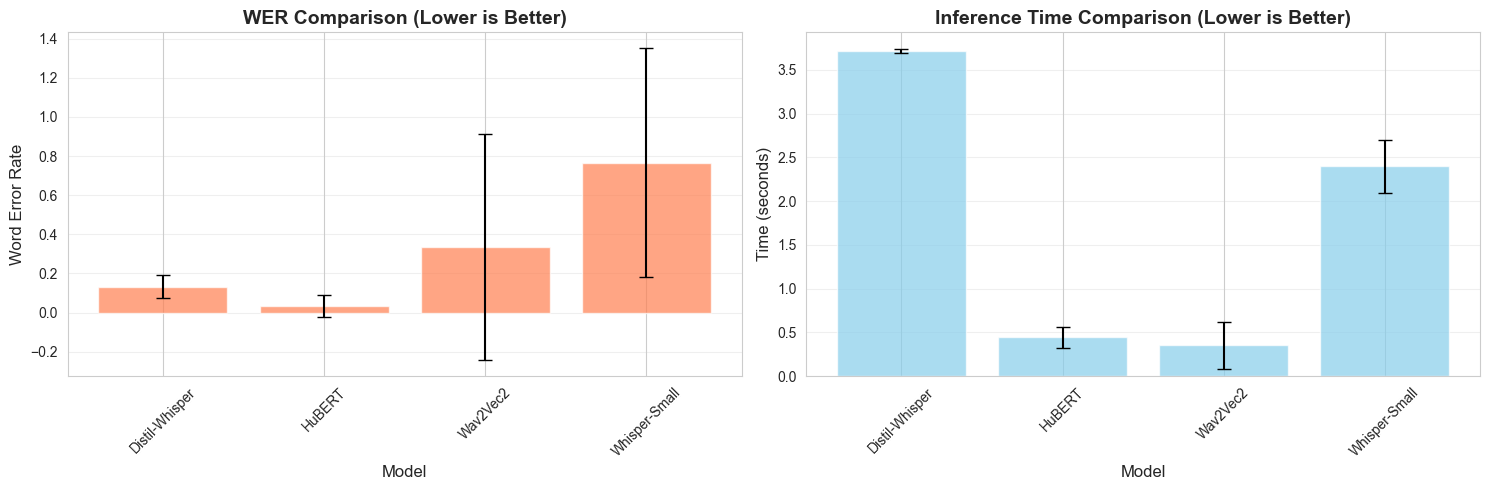

In [12]:
analyzer.plot_comparison(df)

#### 3. View Individual Transcripts

In [13]:
# Show transcripts for the audio file
analyzer.display_transcripts(df, audio_files[2])

,Model,Transcript,WER,Time (s)
8,Wav2Vec2,an unusual sensation on the opposite side of my stomach,0.000,0.21
9,HuBERT,an unusual sensation on the opposite side of my stomach,0.000,0.37
10,Whisper-Small,un unīzūršu senzēšanā ar pārstājiem mājās tomākā.,1.000,2.69
11,Distil-Whisper,an unusual sensation on the opposite side of my stomach.,0.100,3.72


#### 4. Detailed Results Table

In [14]:
# Show full results table
display(HTML("<h5>Complete Results</h5>"))
display(df.style.background_gradient(cmap='RdYlGn_r', subset=['wer'])
        .format({'wer': '{:.3f}', 'time_s': '{:.2f}'}))

,model,audio_path,transcript,time_s,wer
0,Wav2Vec2,data/group_5/01__common_voice_en_18296536.mp3,an unusual sensation on the opposite side of my stomach,0.66,0.000
1,HuBERT,data/group_5/01__common_voice_en_18296536.mp3,an unusual sensation on the opposite side of my stomach,0.58,0.000
2,Whisper-Small,data/group_5/01__common_voice_en_18296536.mp3,an unusual sensation on the opposite side of my stomach.,2.41,0.100
3,Distil-Whisper,data/group_5/01__common_voice_en_18296536.mp3,an unusual sensation on the opposite side of my stomach.,3.74,0.100
4,Wav2Vec2,data/group_5/02__common_voice_en_18297346.mp3,head an doum sur says he should undou buse sile my stumwat,0.19,1.000
5,HuBERT,data/group_5/02__common_voice_en_18297346.mp3,an unusual sensation on the opposite side of my stomac,0.38,0.100
6,Whisper-Small,data/group_5/02__common_voice_en_18297346.mp3,keadaan yang tidak neutral di sisi yang sama di atas kawasan saya.,2.08,1.200
7,Distil-Whisper,data/group_5/02__common_voice_en_18297346.mp3,an unneutral sensation on the opposite side of my stomach.,3.69,0.200
8,Wav2Vec2,data/group_5/03__common_voice_en_18298153.mp3,an unusual sensation on the opposite side of my stomach,0.21,0.000
9,HuBERT,data/group_5/03__common_voice_en_18298153.mp3,an unusual sensation on the opposite side of my stomach,0.37,0.000


#### 5. Save Results

In [15]:

output_path = "notebooks/data/asr_comparison_results.csv"
df.to_csv(output_path, index=False)
print(f"Results saved to: {output_path}")

Results saved to: data/asr_comparison_results.csv


## Step 7: Quick Single Transcription
For testing individual files quickly

In [16]:
def quick_transcribe(audio_path: str, model_name: str = "Distil-Whisper") -> str:
    """Quick transcription helper"""
    result = manager.transcribe(model_name, audio_path)
    print(f"{model_name}: {result.transcript}")
    print(f"    ⏱️ Time: {result.time_seconds:.2f}s")
    return result.transcript

# Example usage:
# quick_transcribe("your_audio.mp3", "Wav2Vec2")

## Final Step: Discussion Questions

1. Which model had the lowest WER?
2. Which was fastest?
3. Do larger models always perform better?
4. How would noise or accents affect performance?
5. Which file type is ideal for ASR (mp3, wav, flac...)?
6. Try running models on your own recordings!